# [Lab Session 3](fourier.ipynb)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.transform import resize

**[Task 1 (a).]()** Load the first image, resize it to (256, 256) and display it.


In [66]:
cell_img = plt.imread('data/cells.png')
cell_img_r = resize(cell_img, (256,256))

**[Task 1 (b).]()** Apply the fast Fourier transform and check the data type of the result.


In [67]:
cell_ft = np.fft.fft2(cell_img_r)


**[Task 1 (c).]()** Extract the phase and amplitude and display them.


In [69]:
amplitude = np.abs(cell_ft)
phase = np.angle(cell_ft)


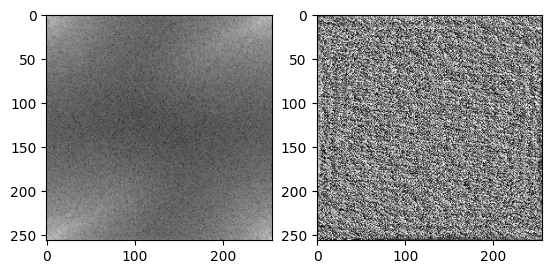

In [70]:
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

**[Task 1 (d).]()** Do a shift so that zero is displayed in the center of the image and show amplitude and phase again.


In [71]:
cell_ft_0 = np.fft.fftshift(cell_ft)

cell_amplitude = np.abs(cell_ft_0)
cell_phase = np.angle(cell_ft_0)

**[Task 1 (e).]()** Apply the inverse FFT and display the restored image.


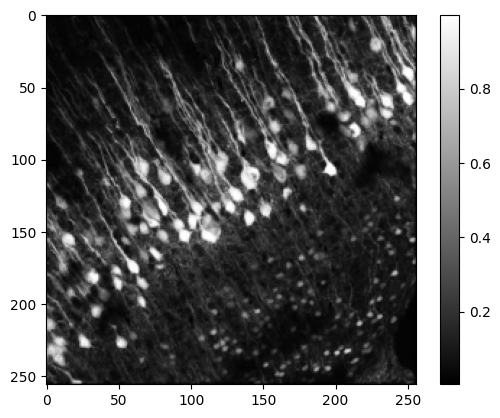

In [73]:
cell_ft_0_1 = np.fft.ifftshift(cell_ft_0)
cell_ft_0_2 = np.fft.ifft2(cell_ft_0_1)

cell_ft_0_3 = cell_ft_0_2.real

plt.figure()
plt.imshow(cell_ft_0_3, 'gray')
plt.colorbar()


---


**[Task 2 (a).]()** Load the brain MR image.


In [109]:
brain_mri = plt.imread('data/brain_mri.png')
r_brain_mri = resize(brain_mri, (256,256))

**[Task 2 (b).]()** Apply the FFT, do a shift, extract amplitude and phase.


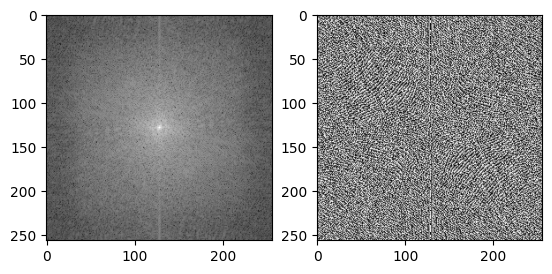

In [74]:
brain_ft = np.fft.fft2(brain_mri)

brain_ft_shift = np.fft.fftshift(brain_ft)


brain_amplitude = np.abs(brain_ft_shift)
brain_phase = np.angle(brain_ft_shift)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(brain_amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(brain_phase, 'gray')



In [75]:
def to_complex_array(amplitude_array, phase_array):
    return amplitude_array * np.exp(1j * phase_array)

**[Task 2 (c).]()** Merge the amplitude of the brain MR image and the phase of cell image. Do the IFFT and display the resulting image.


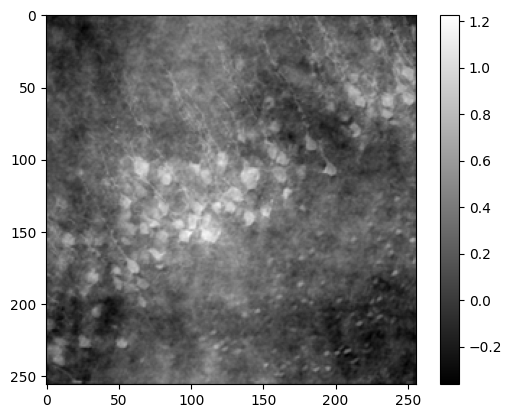

In [76]:
F_merged = to_complex_array(brain_amplitude,cell_phase)

merged_1 = np.fft.ifft2(np.fft.ifftshift(F_merged))
merged_2 = np.real(merged_1)

plt.figure()
plt.imshow(merged_2,'gray')
plt.colorbar()



**[Task 2 (d).]()** Repeat this with the amplitude of the cells and the phase of the brain.


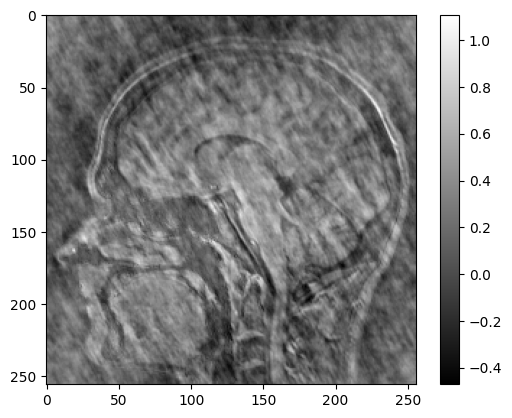

In [78]:
G_merged = to_complex_array(cell_amplitude,brain_phase)

G_merged_1 = np.fft.ifft2(np.fft.ifftshift(G_merged))
G_merged_2 = np.real(G_merged_1)

plt.figure()
plt.imshow(G_merged_2,'gray')
plt.colorbar()

---


**[Task 3 (a).]()** Create a lowpass filter mask.


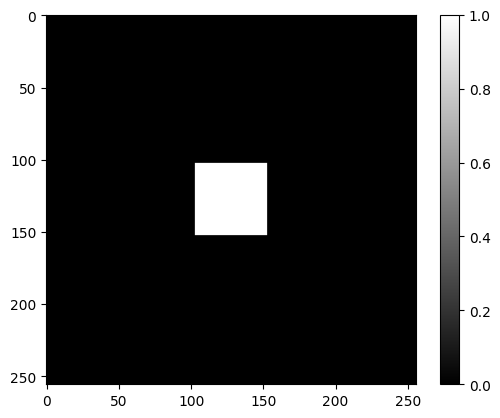

In [92]:
filter_window_size = 50

mask_lp = np.zeros(cell_img_r.shape)

center_y = mask_lp.shape[0] // 2
center_x = mask_lp.shape[1] // 2
half_w = filter_window_size // 2

mask_lp[center_y-half_w:center_y + half_w, center_x - half_w:center_x + half_w] = 1

plt.figure()
plt.imshow(mask_lp, 'gray')
plt.colorbar()

**[Task 3 (b).]()** Create a highpass filter maks.


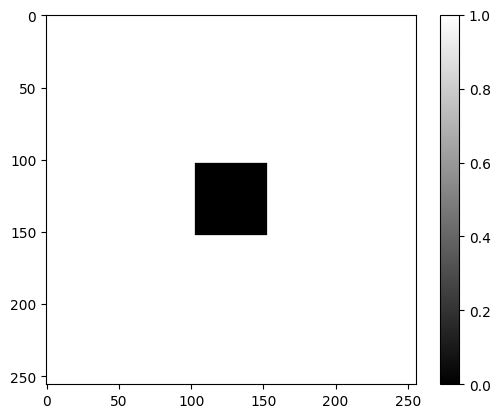

In [93]:
mask_hp = 1 - mask_lp

plt.figure()
plt.imshow(mask_hp, 'gray')
plt.colorbar()

**[Task 3 (c).]()** Apply the lowpass and highpass filter mask to the amplitude of the brain and display the results.


/tmp/ipykernel_1813/2474528299.py:11: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(brain_amp_lp), 'gray')
/tmp/ipykernel_1813/2474528299.py:14: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(brain_amp_hp), 'gray')


Text(0.5, 1.0, 'High-pass')

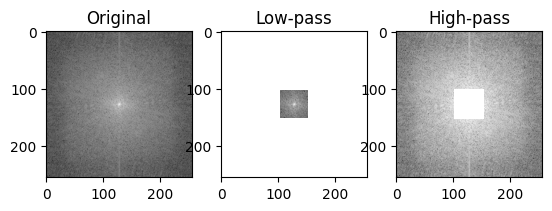

In [95]:
brain_amp_lp = brain_amplitude * mask_lp

brain_amp_hp = brain_amplitude * mask_hp


plt.figure()
plt.subplot(1, 3, 1)
plt.imshow(np.log(brain_amplitude), 'gray')
plt.title('Original')
plt.subplot(1, 3, 2)
plt.imshow(np.log(brain_amp_lp), 'gray')
plt.title('Low-pass')
plt.subplot(1, 3, 3)
plt.imshow(np.log(brain_amp_hp), 'gray')
plt.title('High-pass')


**[Task 3 (d).]()** Apply the mask to the amplitude, merge the result with the phase and restore the image.


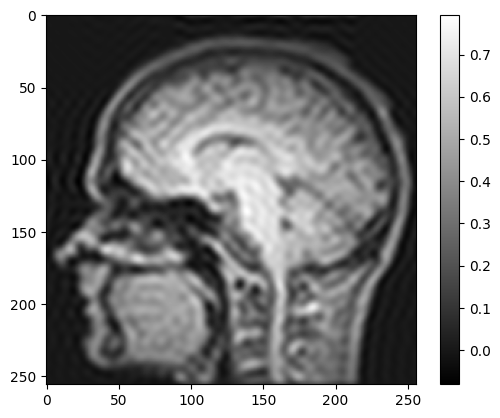

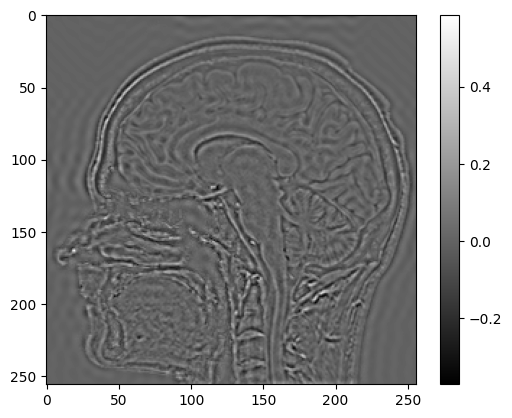

In [97]:
D1_merged = to_complex_array(brain_amp_lp,brain_phase)

D1_merged_1 = np.fft.ifft2(np.fft.ifftshift(D1_merged))
D1_merged_2 = np.real(D1_merged_1)

plt.figure()
plt.imshow(D1_merged_2,'gray')
plt.colorbar()

D2_merged = to_complex_array(brain_amp_hp,brain_phase)

D2_merged_1 = np.fft.ifft2(np.fft.ifftshift(D2_merged))
D2_merged_2 = np.real(D2_merged_1)

plt.figure()
plt.imshow(D2_merged_2,'gray')
plt.colorbar()

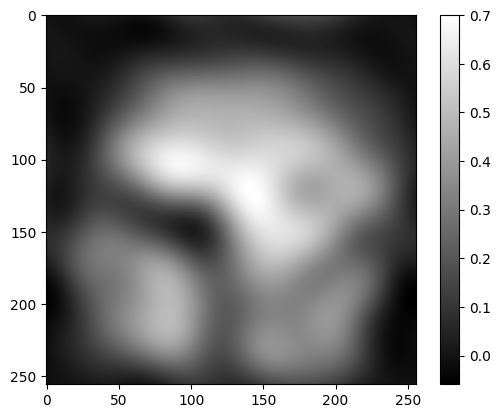

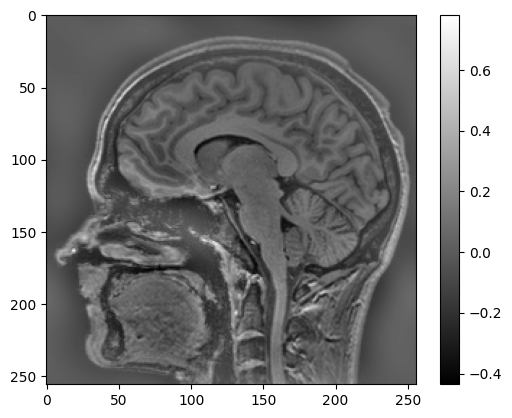

In [99]:
filter_window_size = 10

mask_lp = np.zeros(cell_img_r.shape)

center_y = mask_lp.shape[0] // 2
center_x = mask_lp.shape[1] // 2
half_w = filter_window_size // 2

mask_lp[center_y-half_w:center_y + half_w, center_x - half_w:center_x + half_w] = 1
mask_hp = 1 - mask_lp

brain_amp_lp = brain_amplitude * mask_lp
brain_amp_hp = brain_amplitude * mask_hp

D1_merged = to_complex_array(brain_amp_lp,brain_phase)

D1_merged_1 = np.fft.ifft2(np.fft.ifftshift(D1_merged))
D1_merged_2 = np.real(D1_merged_1)
plt.figure()
plt.imshow(D1_merged_2,'gray')
plt.colorbar()

D2_merged = to_complex_array(brain_amp_hp,brain_phase)

D2_merged_1 = np.fft.ifft2(np.fft.ifftshift(D2_merged))
D2_merged_2 = np.real(D2_merged_1)

plt.figure()
plt.imshow(D2_merged_2,'gray')
plt.colorbar()

---


**[Task 4 (a).]()** Implement a function that computes the 2D-DFT.


In [173]:

def dft2(img):
    M,N = img.shape
    dft = np.zeros (img.shape, dtype=complex)
    x = np.arange (M)[:, None]
    y = np.arange (N)[None, :]
    for u in range (M):
        for v in range (N):
            dft[u,v] = np.sum(img[x,y] * np.exp(-2j * np.pi * (u *x / M + v *y/N)))/ (M*N)
    return dft

**[Task 4 (b).]()** Implement a function that computes the 2D-IDFT.


In [163]:

def idft2(dft):
    M,N = dft.shape
    idft = np.zeros (dft.shape, dtype=complex)
    x = np.arange (M)[:, None]
    y = np.arange (N)[None, :]
    for u in range (M):
        for v in range (N):
            idft[u,v] = np.sum(dft[x,y] * np.exp(2j * np.pi * (u *x / M + v *y/N)))
    return idft

Due to high computational costs, we need to resize the image.


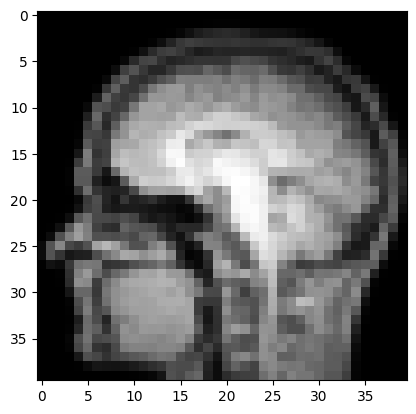

In [107]:
test_img = resize(brain_mri, (40, 40))
plt.imshow(test_img, 'gray')

**[Task 4 (c).]()** Apply your DFT implementation to the image and display amplitude and phase.


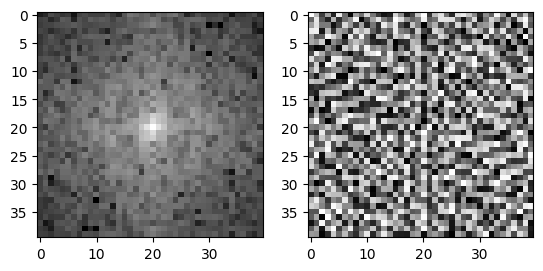

In [ ]:
test_img

C_dft = dft2(test_img)
shifted = np.fft.fftshift(C_dft)

C_amplitude = np.abs(shifted)
C_phase = np.angle(shifted)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(C_amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(C_phase, 'gray')



**[Task 4 (d).]()** Reconstruct the image using your IDFT implementation and display it.


In [156]:
H_merged = to_complex_array(C_amplitude,C_phase)
H_merged_shift = np.fft.ifftshift(H_merged)
H_merged_invers = idft2(H_merged_shift)
H_merged_real = H_merged_invers.real

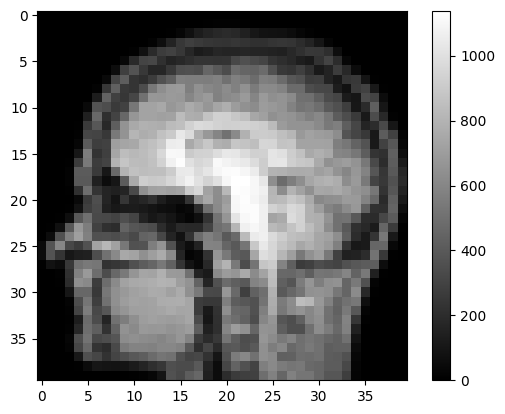

In [164]:
H_merged = to_complex_array(C_amplitude,C_phase)
H_merged_shift = np.fft.ifftshift(H_merged)
H_merged_invers = idft2(H_merged_shift)
H_merged_real = H_merged_invers.real


plt.figure()
plt.imshow(H_merged_real,'gray')
plt.colorbar()

**[Task 4 (e).]()** Compare your result to the result of numpy's FFT


In [174]:
np_fft = np.fft.fft2(test_img, norm = 'forward')
CC_dft = dft2(test_img)




print(np.allclose(CC_dft, np_fft))

True


**[Task 4 (f).]()** Round the arrays and compare them again.


In [180]:
mean_dft_fft = np.mean(np.abs(CC_dft - np_fft))
print(mean_dft_fft)

round_dft = np.round(CC_dft,5)
round_fft = np.round (np_fft, 5)

(round_dft == round_fft).all()



7.525284431170575e-17


True

**[Task 4 (g).]()** Compare the run times of the two algorithms (your DFT and numpy's FFT)


In [181]:
%timeit dft2(test_img)
%timeit np.fft.fft2(test_img, norm ='forward')

133 ms ± 6.72 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
41.3 μs ± 12 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)
